
# Project: No Show Appointments Data Analysis

## Table of Contents
<ul>
<li><a href="#intro">Introduction</a></li>
<li><a href="#wrangling">Data Wrangling</a></li>
<li><a href="#eda">Exploratory Data Analysis</a></li>
<li><a href="#conclusions">Conclusions</a></li>
</ul>

<a id='intro'></a>
## Introduction

### Dataset Description 

In this project we'll explore a dataset collects information from 100K medical appointments in Brazil & is focused on the question of whether or not patients show up for their appointment. A number of characteristics about the patient are included in each row.
<li>ScheduledDay tells us on what day the patient set up their appointment.</li>
<li>Neighborhood indicates the location of the hospital.</li>
<li>Scholarship’ indicates whether or not the patient is enrolled in Brazilian welfare program.</li>
<li>No_show  indicates whether the patients were 'present' or 'absent' at their appointments. 'yes' stands for 'absent' & 'No' stands for 'present'.</li>


### Question(s) for Analysis
#### Questions 1:
<li>What is the percentage of present & absent patients?</li>

#### Question 2:
<li>What factors are important for us to know in order to predict if a patient will show up for their scheduled appointment?</li>

#### Question 3:
<li>In Which day are the most appointment made? How was the attendance rate for each day?</li>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

<a id='wrangling'></a>
## Data Wrangling
In This section we'll first load our data and take a look in it and see which data is useful to us & which is not. Also we'll look for any incomplete or missing data and try to fix it.

In [2]:
# Load your data and print out a few lines. Perform operations to inspect data
#   types and look for instances of missing or possibly errant data.
df = pd.read_csv('../data/noshowappointments-kagglev2-may-2016.csv')

In [3]:
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [4]:
# Gives us the num of rows & columns in the dataset
df.shape

(110527, 14)

In [5]:
# Check for duplicate data
df.duplicated().sum()

np.int64(0)

There is no duplicated data.

In [6]:
df.describe()

,PatientId,AppointmentID,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,1.105270e+05,1.105270e+05,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.088874,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110205,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


As .info() shows us there is no missing data.


### Data Cleaning
In the following cells we'll drop the non important columns,
rename the columns & replace no_show data for better understanding
 

In [8]:
# Drop those columns that are not important for the analysis
df.drop(['PatientId', 'AppointmentID'], axis=1, inplace=True)
df.head()

,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [9]:
df.rename(columns=lambda x: x.strip().lower().replace("-", "_"), inplace=True)
df.head()

,gender,scheduledday,appointmentday,age,neighbourhood,scholarship,hipertension,diabetes,alcoholism,handcap,sms_received,no_show
0,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [10]:
df['age'].unique()

array([ 62,  56,   8,  76,  23,  39,  21,  19,  30,  29,  22,  28,  54,
        15,  50,  40,  46,   4,  13,  65,  45,  51,  32,  12,  61,  38,
        79,  18,  63,  64,  85,  59,  55,  71,  49,  78,  31,  58,  27,
         6,   2,  11,   7,   0,   3,   1,  69,  68,  60,  67,  36,  10,
        35,  20,  26,  34,  33,  16,  42,   5,  47,  17,  41,  44,  37,
        24,  66,  77,  81,  70,  53,  75,  73,  52,  74,  43,  89,  57,
        14,   9,  48,  83,  72,  25,  80,  87,  88,  84,  82,  90,  94,
        86,  91,  98,  92,  96,  93,  95,  97, 102, 115, 100,  99,  -1])

In [11]:
# Drop the rows that contains age less than 0
df.drop(df[(df.age < 0)].index, inplace = True)

In [12]:
df['age'].unique()

array([ 62,  56,   8,  76,  23,  39,  21,  19,  30,  29,  22,  28,  54,
        15,  50,  40,  46,   4,  13,  65,  45,  51,  32,  12,  61,  38,
        79,  18,  63,  64,  85,  59,  55,  71,  49,  78,  31,  58,  27,
         6,   2,  11,   7,   0,   3,   1,  69,  68,  60,  67,  36,  10,
        35,  20,  26,  34,  33,  16,  42,   5,  47,  17,  41,  44,  37,
        24,  66,  77,  81,  70,  53,  75,  73,  52,  74,  43,  89,  57,
        14,   9,  48,  83,  72,  25,  80,  87,  88,  84,  82,  90,  94,
        86,  91,  98,  92,  96,  93,  95,  97, 102, 115, 100,  99])

We'll work with age from 0 to 115.

In [13]:
# Replace no_show data for better understanding
# Replace Gender categories
df['no_show'] = df['no_show'].replace({'No':'Present', 'Yes':'Absent'})
df['gender'] = df['gender'].replace({'F':'Female', 'M':'Male'})

In [14]:
df.head()

,gender,scheduledday,appointmentday,age,neighbourhood,scholarship,hipertension,diabetes,alcoholism,handcap,sms_received,no_show
0,Female,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,Present
1,Male,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,Present
2,Female,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,Present
3,Female,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,Present
4,Female,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,Present


<a id='eda'></a>
## Exploratory Data Analysis
In this section we'll observe the data we cleaned earlier and ask some questions and try to answer them by using box plots, Bar & Pie charts and histograms.
### Research Question 1
<li>(What is the percentage of present & absent patients?)</li>

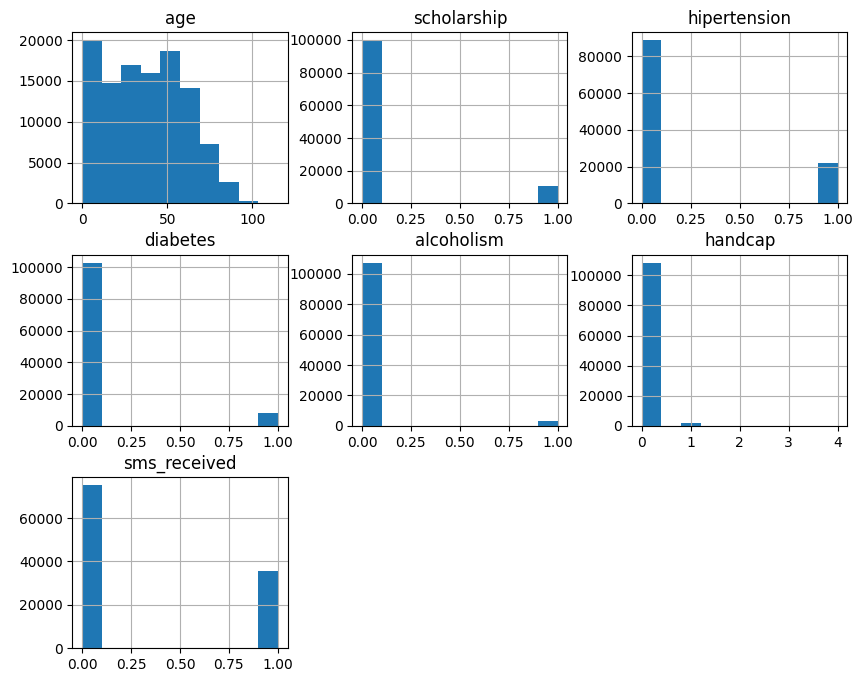

In [15]:
# Exploring the data distribution for each variable
df.hist(figsize=(10, 8));

In [16]:
present = (df.no_show == 'Present').sum()
present

np.int64(88207)

In [17]:
absent = (df.no_show == 'Absent').sum()
absent

np.int64(22319)

In [18]:
# Percentage of present & absent
(present/(present + absent)*100, absent/(present + absent)*100)

(np.float64(79.80656135208005), np.float64(20.193438647919944))

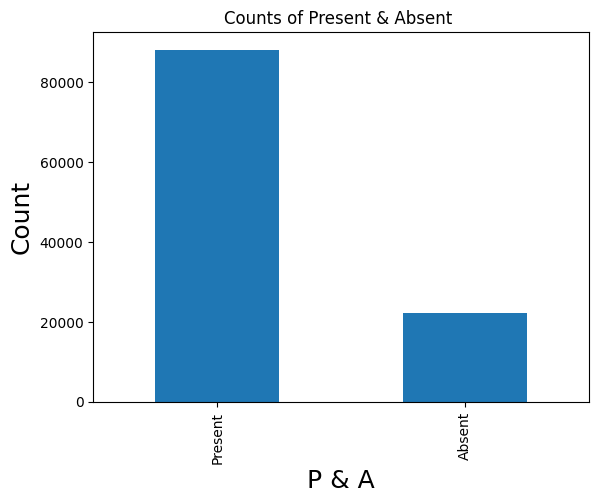

In [19]:
# Plotting bar chart for the present & absent
df['no_show'].value_counts().plot(kind='bar', title = 'Counts of Present & Absent ')
plt.xlabel('P & A', fontsize=18)
plt.ylabel('Count', fontsize=18);

This bar chart shows us that the amount of people who attended their appointment are greater than who did not.

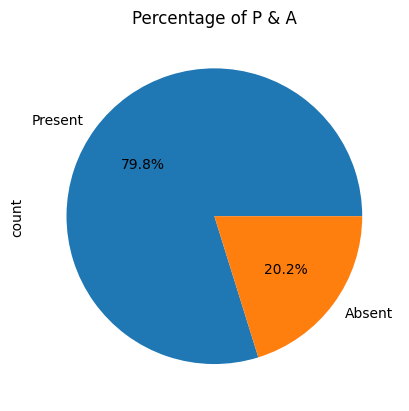

In [20]:
# Plotting pie chart for the present & absent
df['no_show'].value_counts().plot(kind='pie', title = 'Percentage of P & A', autopct='%1.1f%%');

### Result:
The analysis done above shows us that most of the patients really did attended their appointments. The numbers tells us that (79.8%) of the patients attended their appointments & (20.2%) did not. 

### Research Question 2:
<li>What factors are important for us to know in order to predict if a patient will show up for their scheduled appointment?</li>

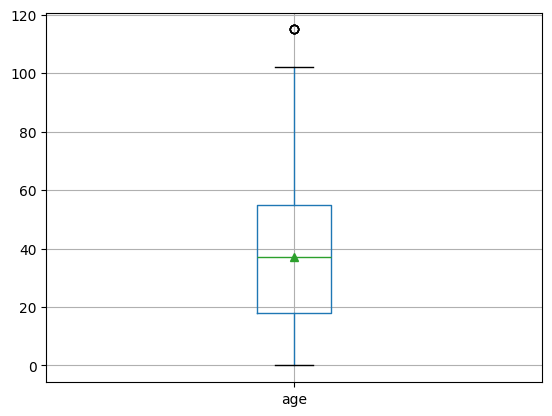

In [21]:
# boxplot for age
df.boxplot(['age'], showmeans=True);

We can see here that the mean age is 37.09 (37.089219).

In [22]:
# Function for bar plot to escape the repetitive code
def plot_bar(variable):
    df.groupby([variable, 'no_show']).size().unstack('no_show').plot(kind='bar', rot=0, title = 'Counts by '+variable+ ' Showing Up')
    plt.xlabel(variable, fontsize=18)
    plt.ylabel('Count', fontsize=18);

In [23]:
# Function for pie plot to escape the repetitive code
def plot_pie(variable):
    df.groupby([variable, 'no_show']).count()['age'].plot(kind='pie', title = 'Percentage by '+variable+ ' Showing Up', autopct='%1.1f%%')
    plt.ylabel('');

In [24]:
# Function for the attendance rate (present / all appointments) of each group
def attendance_rate(variable):
    t = df.groupby(variable)['no_show'].agg(appointments='count', present=lambda s: (s == 'Present').sum())
    t['attendance_rate_%'] = (t['present'] / t['appointments'] * 100).round(1)
    return t

### Gender

In [25]:
# Count num of absent & present females & males
df.groupby(['gender', 'no_show']).size().unstack('gender')

gender,Female,Male
no_show,,
Absent,14594,7725
Present,57245,30962


In [26]:
df.groupby(['gender', 'no_show']).size().unstack('gender').apply(lambda x:x/x.sum())

gender,Female,Male
no_show,,
Absent,0.203149,0.199679
Present,0.796851,0.800321


In [27]:
attendance_rate('gender')

,appointments,present,attendance_rate_%
gender,,,
Female,71839,57245,79.7
Male,38687,30962,80.0


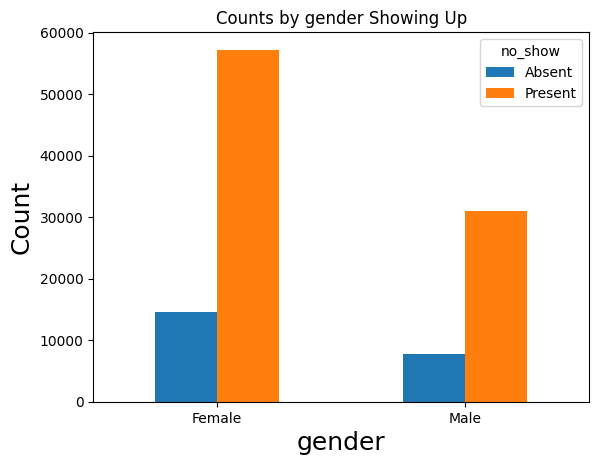

In [28]:
# Bar & Pie charts for variable 'gender' with no_show
plot_bar('gender')

This bar chart shows more females than males, both present and absent. That is because there are more female appointments (71,839 vs 38,687). The attendance rate is almost the same for both: 79.7% for females and 80.0% for males (see the table above).

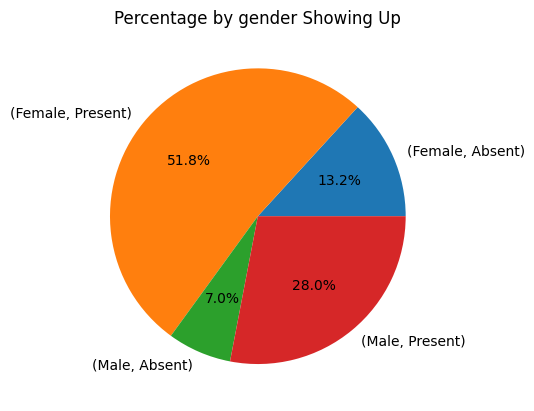

In [29]:
plot_pie('gender')

This pie chart show us the percentage of the attendance of females & males for their appointments.

### Scholarship

In [30]:
df.groupby(['scholarship', 'no_show']).size().unstack('scholarship')

scholarship,0,1
no_show,,
Absent,19741,2578
Present,79924,8283


In [31]:
attendance_rate('scholarship')

,appointments,present,attendance_rate_%
scholarship,,,
0,99665,79924,80.2
1,10861,8283,76.3


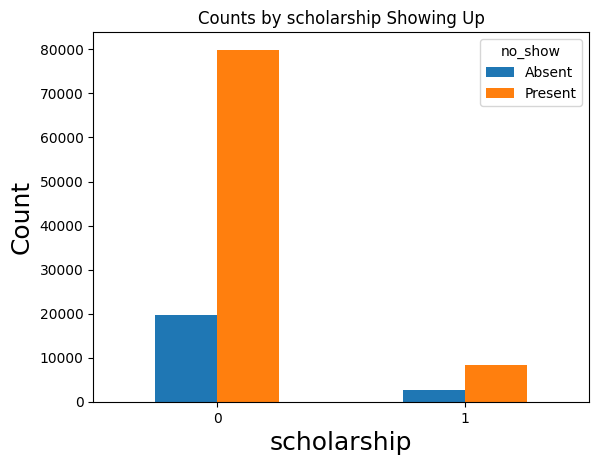

In [32]:
# Bar & Pie charts for variable 'scholarship' with no_show
plot_bar('scholarship')

The counts alone do not show it, but the attendance rate table above does: patients with a scholarship attended less (76.3%) than patients without one (80.2%).

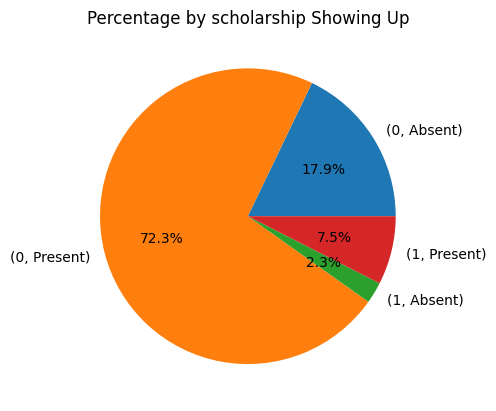

In [33]:
plot_pie('scholarship')

This chart shows us the attendance of the patients filtered by scholarships.

### Hypertension (column name in the data: hipertension)

In [34]:
df.groupby(['hipertension', 'no_show']).size().unstack('hipertension')

hipertension,0,1
no_show,,
Absent,18547,3772
Present,70178,18029


In [35]:
attendance_rate('hipertension')

,appointments,present,attendance_rate_%
hipertension,,,
0,88725,70178,79.1
1,21801,18029,82.7


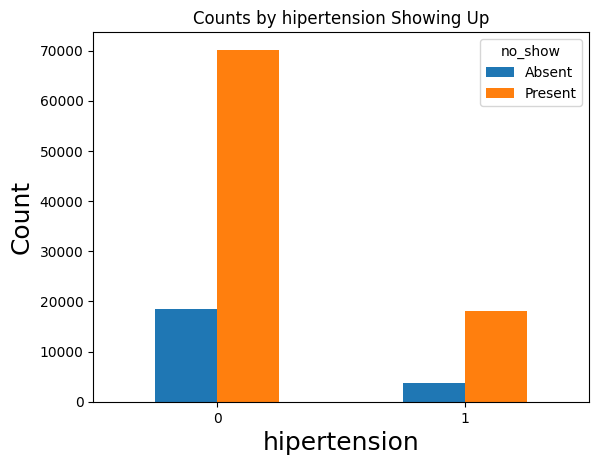

In [36]:
# Bar & Pie charts for variable 'hipertension' with no_show
plot_bar('hipertension')

Patients without hypertension have more present patients in the chart because there are many more of them (88,725 vs 21,801). By attendance rate, patients with hypertension attended slightly more: 82.7% vs 79.1%. This was not checked against age.

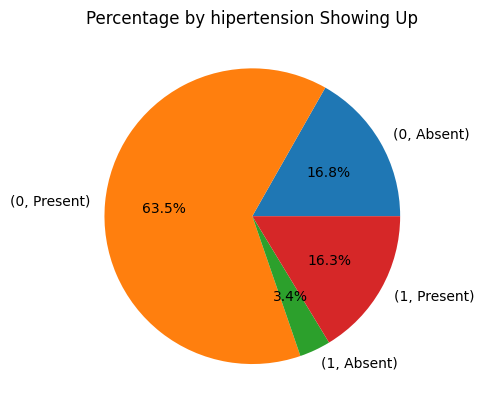

In [37]:
plot_pie('hipertension')

This chart shows us the attendance of the patients filtered by hipertension.

### Diabetes

In [38]:
df.groupby(['diabetes', 'no_show']).size().unstack('diabetes')

diabetes,0,1
no_show,,
Absent,20889,1430
Present,81694,6513


In [39]:
attendance_rate('diabetes')

,appointments,present,attendance_rate_%
diabetes,,,
0,102583,81694,79.6
1,7943,6513,82.0


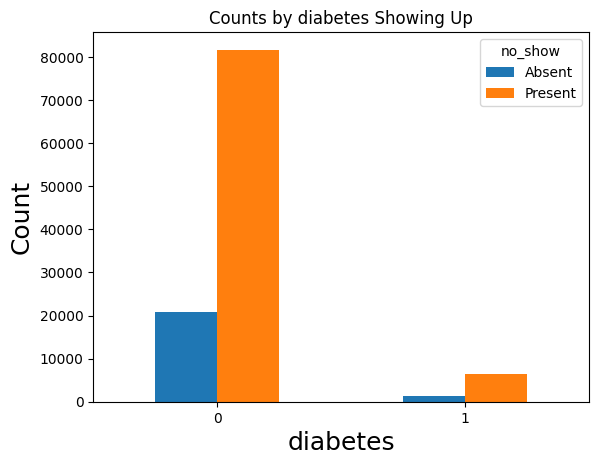

In [40]:
# Bar & Pie charts for variable 'diabetes' with no_show
plot_bar('diabetes')

Patients without diabetes have more present patients in the chart because there are many more of them (102,583 vs 7,943). By attendance rate, patients with diabetes attended slightly more: 82.0% vs 79.6%. This was not checked against age.

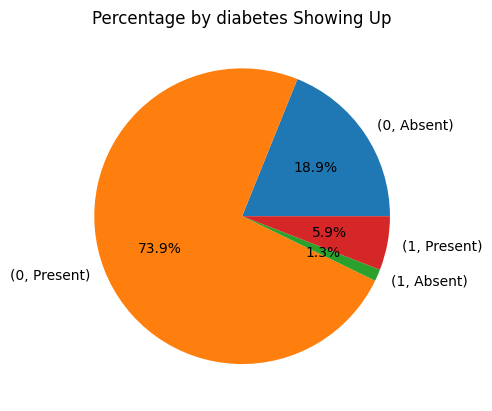

In [41]:
plot_pie('diabetes')

This chart shows us the attendance of the patients filtered by diabetes.

### Alcoholism

In [42]:
df.groupby(['alcoholism', 'no_show']).size().unstack('alcoholism')

alcoholism,0,1
no_show,,
Absent,21642,677
Present,85524,2683


In [43]:
attendance_rate('alcoholism')

,appointments,present,attendance_rate_%
alcoholism,,,
0,107166,85524,79.8
1,3360,2683,79.9


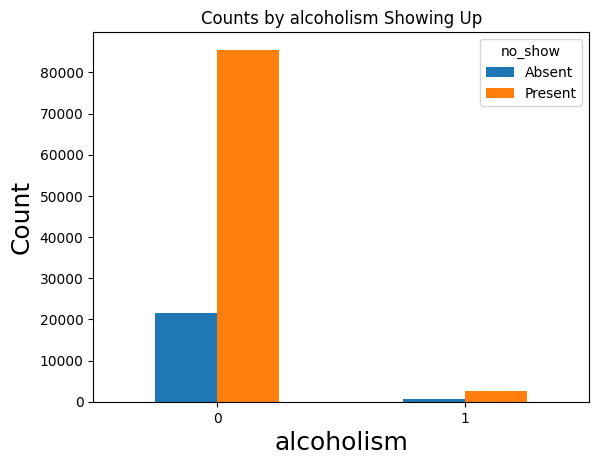

In [44]:
# Bar & Pie charts for variable 'alcoholism' with no_show
plot_bar('alcoholism')

The chart shows more present patients without alcohol addiction only because there are far more of them (107,166 vs 3,360). The attendance rate is almost the same: 79.8% without and 79.9% with alcohol addiction. Alcoholism does not separate present from absent patients in this data.

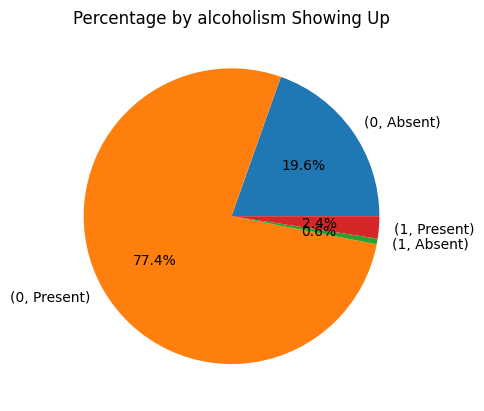

In [45]:
plot_pie('alcoholism')

This chart shows us the attendance of the patients filtered by alcoholism.

### Handicap (column name in the data: handcap)

In [46]:
df.groupby(['handcap', 'no_show']).size().unstack('handcap')

handcap,0,1,2,3,4
no_show,,,,,
Absent,21912,366,37,3,1
Present,86373,1676,146,10,2


In [47]:
attendance_rate('handcap')

,appointments,present,attendance_rate_%
handcap,,,
0,108285,86373,79.8
1,2042,1676,82.1
2,183,146,79.8
3,13,10,76.9
4,3,2,66.7


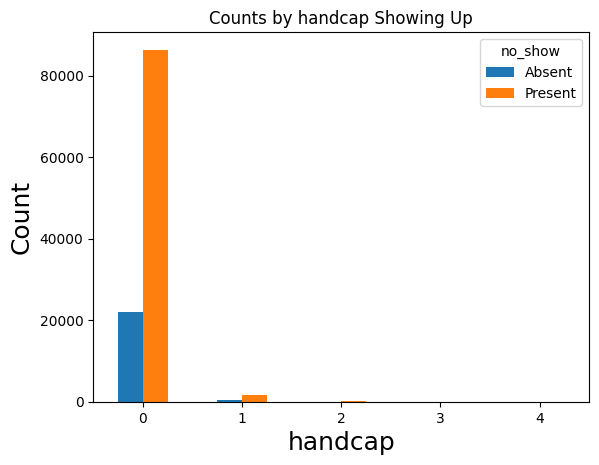

In [48]:
# Bar & Pie charts for variable 'handcap' with no_show
plot_bar('handcap')

The chart shows more present patients without handicap only because there are far more of them (108,285 of 110,526). The attendance rate is 79.8% without handicap and 82.1% for handicap level 1. Levels 2, 3 and 4 have very few patients (183, 13 and 3), so their rates (79.8%, 76.9%, 66.7%) say little. Any handicap together: 81.8%. Handicap is not a strong factor in this data.

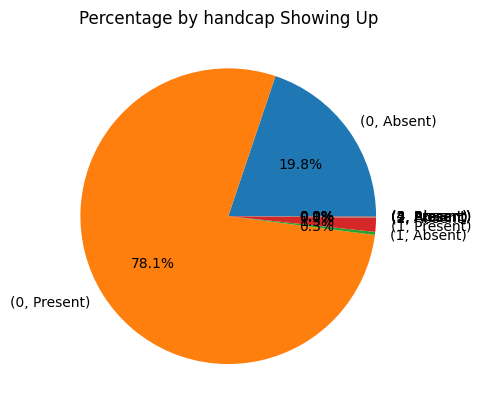

In [49]:
plot_pie('handcap')

This chart shows us the attendance of the patients filtered by handcap.

### sms_received

In [50]:
df.groupby(['sms_received', 'no_show']).size().unstack('sms_received')

sms_received,0,1
no_show,,
Absent,12535,9784
Present,62509,25698


In [51]:
attendance_rate('sms_received')

,appointments,present,attendance_rate_%
sms_received,,,
0,75044,62509,83.3
1,35482,25698,72.4


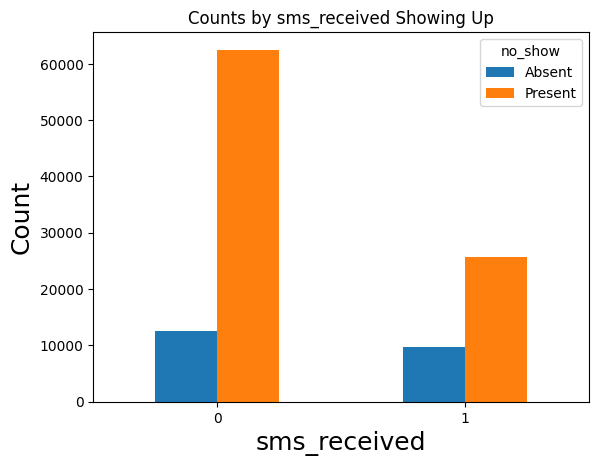

In [52]:
# Bar & Pie charts for variable 'sms_received' with no_show
plot_bar('sms_received')

The chart shows more absent and more present patients among those who did not receive an SMS, because most appointments had no SMS (75,044 vs 35,482). By attendance rate, patients who received an SMS attended less: 72.4% vs 83.3% for patients who did not. This does not mean the SMS caused it. The reason was not investigated here.

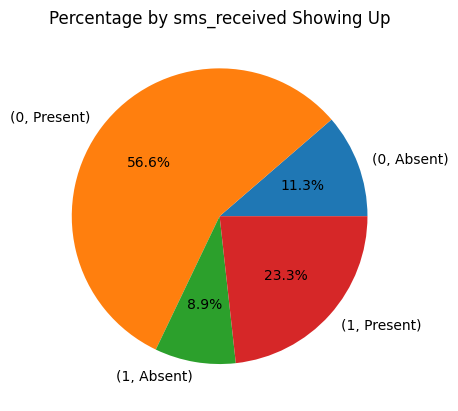

In [53]:
plot_pie('sms_received')

This chart shows us the attendance of the patients filtered by sms_received.

### Result:
<li>Attendance rate by variable (present patients / all appointments in the group) is in the tables above. Differences between the groups are small for most variables.</li>
<li>The biggest gap is sms_received: 72.4% with an SMS vs 83.3% without (10.9 points).</li>
<li>Next are scholarship (76.3% with vs 80.2% without, 3.9 points) and hipertension (82.7% with vs 79.1% without, 3.6 points).</li>
<li>Diabetes (82.0% vs 79.6%), handicap (any handicap 81.8% vs 79.8%), gender (79.7% female vs 80.0% male) and alcoholism (79.9% vs 79.8%) show small or no differences.</li>
<li>These are differences in a single variable at a time. No test or model was run, so none of them is shown to predict attendance.</li>

### Research Question 3
<li>Which day are the most appointment made? How was the attendance rate for each day?</li>

In [54]:
# Change the appointmentday data type from object to datetime
df['appointmentday'] = pd.to_datetime(df['appointmentday'])

In [55]:
# Create new column name 'weekday' from 0 to 6 where 0 is Monday 6 is Sunday
df['weekday']=df['appointmentday'].dt.dayofweek

##### Note:
0:Monday  1:Tuesday  2:Wednesday  3:Thursday  4:Friday  5:Saturday  6:Sunday

In [56]:
df.head()

,gender,scheduledday,appointmentday,age,neighbourhood,scholarship,hipertension,diabetes,alcoholism,handcap,sms_received,no_show,weekday
0,Female,2016-04-29T18:38:08Z,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,Present,4
1,Male,2016-04-29T16:08:27Z,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,Present,4
2,Female,2016-04-29T16:19:04Z,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,Present,4
3,Female,2016-04-29T17:29:31Z,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,Present,4
4,Female,2016-04-29T16:07:23Z,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,Present,4


In [57]:
# The total count of appointments made by day
df_day = df.groupby(['weekday']).count()['age']
df_day

weekday
0    22714
1    25640
2    25867
3    17247
4    19019
5       39
Name: age, dtype: int64

In [58]:
attendance_rate('weekday')

,appointments,present,attendance_rate_%
weekday,,,
0,22714,18024,79.4
1,25640,20488,79.9
2,25867,20774,80.3
3,17247,13909,80.6
4,19019,14982,78.8
5,39,30,76.9


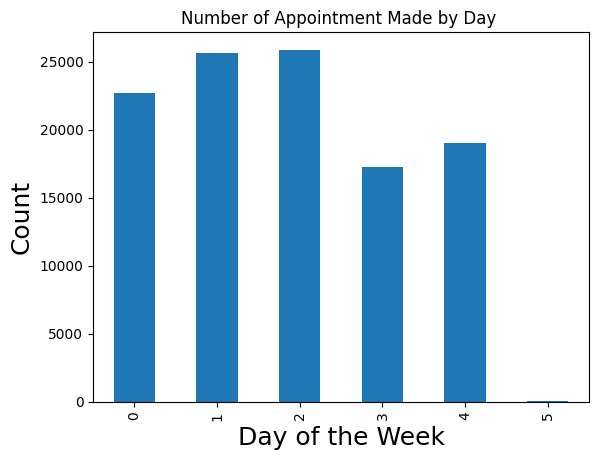

In [59]:
# Bar & Pie charts to observe the total count of appointments made by day
df_day.plot(kind='bar', title = 'Number of Appointment Made by Day ')
plt.xlabel('Day of the Week', fontsize=18)
plt.ylabel('Count', fontsize=18);

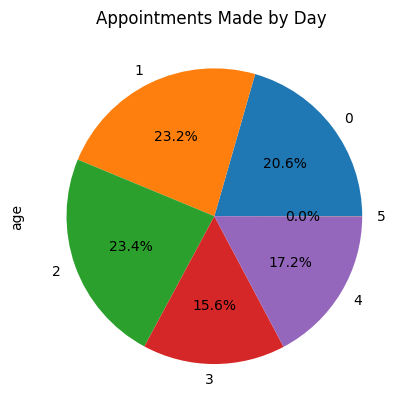

In [60]:
df_day.plot(kind='pie', title = 'Appointments Made by Day ', autopct='%1.1f%%');

### Result:
Wednesday was the day with the highest total amount of appointments, which is 25867 (23.4%). Tuesday comes next with 25640 (23.2%). The lowest total is Saturday with 39 and there is no record on Sunday.

The attendance rate is similar on every day from Monday to Friday (78.8% to 80.6%). Saturday is 76.9%, but it has only 39 appointments.

<a id='conclusions'></a>
## Conclusions
At the end of this project we have a clearer view of the data we investigated. Here is a brief of what we observed:
<li>For the first question, most of the patients attended their appointments, with a percentage of 79.8% (20.2% did not).</li>
<li>For the second question, the differences in attendance rate between groups are small for most variables. The largest is sms_received (72.4% attendance with an SMS vs 83.3% without), then scholarship (76.3% with vs 80.2% without) and hipertension (82.7% with vs 79.1% without). Alcoholism (79.9% vs 79.8%) and gender (79.7% vs 80.0%) show almost no difference.</li>
<li>For the third question, Wednesday had the most appointments (25867) and Saturday the fewest (39), with no record on Sunday. The attendance rate is about the same on all weekdays (78.8% to 80.6%).</li>


### Limitations
<li>The analysis looks at one variable at a time. No statistical test or model was used, so the results describe this data only and do not show a cause.</li>
<li>The SMS result is the opposite of what we would expect. It was not investigated here (for example, whether patients who received an SMS booked further ahead).</li>
<li>Age was not compared with the other variables, so the hipertension and diabetes results may partly reflect age.</li>
<li>Saturday has only 39 appointments and handicap levels 2, 3 and 4 have 183, 13 and 3, so their rates are not reliable.</li>
<li>5 rows have an appointment day before the scheduled day. They were kept.</li>